In [2]:
# %%
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display
import warnings
warnings.filterwarnings('ignore')

# ── parameters matching the C code ──────────────────────────────────────────
NX        = 20          # interior rows    (i = 1..NX)
NY        = 20          # interior cols    (j = 1..NY)
N_THREADS = 4           # OMP_NUM_THREADS

# ── flat array dimensions (with ghost border) ────────────────────────────────
ROWS = NX + 2           # 0..NX+1
COLS = NY + 2           # 0..NY+1
N    = ROWS * COLS      # total elements

def k(i, j): return (NY + 2) * i + j   # row-major index, same as C code

# ── collapse(2): build the full ordered list of (i,j) work items ─────────────
# OpenMP iterates i from 1..NX, j from 1..NY in row-major order,
# then assigns chunks of size ceil(NX*NY / N_THREADS) to each thread.
work_items = [(i, j) for i in range(1, NX + 1) for j in range(1, NY + 1)]
total_items  = len(work_items)                      # NX * NY
chunk        = (total_items + N_THREADS - 1) // N_THREADS

thread_of = {}   # (i,j) -> thread id
for t in range(N_THREADS):
    for idx in range(t * chunk, min((t + 1) * chunk, total_items)):
        thread_of[work_items[idx]] = t

print(f"Grid (with ghosts): {ROWS} x {COLS}  =  {N} doubles  =  {N*8/1024:.1f} KB")
print(f"Interior cells: {NX} x {NY} = {total_items}")
print(f"Chunk size per thread (static): {chunk} cells")
for t in range(N_THREADS):
    owned = [w for w in work_items if thread_of[w] == t]
    rows_owned = sorted(set(i for i,j in owned))
    print(f"  Thread {t}: {len(owned)} cells,  rows {rows_owned[0]}..{rows_owned[-1]}")


Grid (with ghosts): 22 x 22  =  484 doubles  =  3.8 KB
Interior cells: 20 x 20 = 400
Chunk size per thread (static): 100 cells
  Thread 0: 100 cells,  rows 1..5
  Thread 1: 100 cells,  rows 6..10
  Thread 2: 100 cells,  rows 11..15
  Thread 3: 100 cells,  rows 16..20


### 1 — Thread ownership map

In [ ]:
# %%
# ── build ownership matrix (full ROWS x COLS grid) ───────────────────────────
owner = np.full((ROWS, COLS), -1, dtype=int)   # -1 = ghost / boundary
for (i, j), t in thread_of.items():
    owner[i, j] = t

thread_colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52',
                 '#8172B2', '#937860', '#DA8BC3', '#8C8C8C']
ghost_color   = '#E8E8E8'
bound_color   = '#2C2C2C'

# map to RGBA
import matplotlib as mpl
rgba = np.zeros((ROWS, COLS, 4))
ghost_rgba = mpl.colors.to_rgba(ghost_color)

for r in range(ROWS):
    for c in range(COLS):
        t = owner[r, c]
        if t == -1:
            rgba[r, c] = ghost_rgba
        else:
            rgba[r, c] = mpl.colors.to_rgba(thread_colors[t % len(thread_colors)])

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(rgba, aspect='equal', origin='upper')

# draw grid lines
for x in np.arange(-0.5, COLS, 1):
    ax.axvline(x, color='white', linewidth=0.4)
for y in np.arange(-0.5, ROWS, 1):
    ax.axhline(y, color='white', linewidth=0.4)

# annotate each interior cell with its flat index k
for i in range(1, NX + 1):
    for j in range(1, NY + 1):
        ax.text(j, i, str(k(i,j)), ha='center', va='center',
                fontsize=5.5, color='white', fontweight='bold')

# thick borders between thread bands
for t in range(N_THREADS - 1):
    last_idx = (t + 1) * chunk - 1
    if last_idx < total_items:
        border_i, border_j = work_items[last_idx]
        # if j==NY the band break is at a full row boundary
        if border_j == NY:
            ax.axhline(border_i + 0.5, color='black', linewidth=2.5)
        else:
            # partial row: draw an L-shaped border
            ax.plot([border_j + 0.5, COLS - 0.5], [border_i + 0.5, border_i + 0.5],
                    color='black', linewidth=2.5)
            ax.plot([border_j + 0.5, border_j + 0.5], [border_i + 0.5, border_i + 1.5],
                    color='black', linewidth=2.5)
            ax.plot([-0.5, border_j + 0.5], [border_i + 1.5, border_i + 1.5],
                    color='black', linewidth=2.5)

# legend
patches = [mpatches.Patch(color=thread_colors[t], label=f'Thread {t}  ({chunk} cells)')
           for t in range(N_THREADS)]
patches.append(mpatches.Patch(color=ghost_color, label='Ghost / boundary (not computed)'))
ax.legend(handles=patches, loc='upper right', bbox_to_anchor=(1.38, 1.0), fontsize=9)

ax.set_title(f'collapse(2) schedule(static): thread ownership\n'
             f'NX={NX}, NY={NY}, {N_THREADS} threads — numbers = flat index k=(NY+2)*i+j',
             fontsize=11)
ax.set_xlabel('column j   (0=left ghost, NY+1=right ghost)')
ax.set_ylabel('row i   (0=top ghost, NX+1=bottom ghost)')
ax.set_xticks(range(COLS)); ax.set_xticklabels(range(COLS), fontsize=7)
ax.set_yticks(range(ROWS)); ax.set_yticklabels(range(ROWS), fontsize=7)
plt.tight_layout()
plt.savefig('plots/collapse2_ownership.png', dpi=150, bbox_inches='tight')
plt.show()


### 2 — Stencil memory footprint per thread

In [ ]:

import os

# ── animation: step through every interior cell, light up the 5-point stencil
fig2, ax2 = plt.subplots(figsize=(9, 9))

# base ownership image (desaturated)
rgba_base = rgba.copy()
rgba_base[..., :3] = rgba_base[..., :3] * 0.45 + 0.55   # lighten
im = ax2.imshow(rgba_base, aspect='equal', origin='upper', animated=True)

for x in np.arange(-0.5, COLS, 1):
    ax2.axvline(x, color='white', linewidth=0.4)
for y in np.arange(-0.5, ROWS, 1):
    ax2.axhline(y, color='white', linewidth=0.4)

highlight_patches = []
title2 = ax2.set_title('')

STENCIL_COLORS = {
    'center':  '#FF0000',
    'left':    '#FFA500',
    'right':   '#FFA500',
    'above':   '#9B59B6',
    'below':   '#9B59B6',
}

# show every 5th cell to keep the animation a reasonable length
step = max(1, total_items // 60)
frames = list(range(0, total_items, step))

def make_rect(row, col, color, alpha=0.85):
    return mpatches.FancyBboxPatch(
        (col - 0.45, row - 0.45), 0.9, 0.9,
        boxstyle='round,pad=0.05',
        facecolor=color, edgecolor='black', linewidth=1.2,
        alpha=alpha, zorder=3)

def animate(frame_idx):
    idx = frames[frame_idx]
    i, j = work_items[idx]
    t    = thread_of[(i, j)]

    for p in highlight_patches:
        p.remove()
    highlight_patches.clear()

    stencil = [
        (i,   j,   'center'),
        (i,   j-1, 'left'),
        (i,   j+1, 'right'),
        (i-1, j,   'above'),
        (i+1, j,   'below'),
    ]
    for (ri, rj, label) in stencil:
        p = make_rect(ri, rj, STENCIL_COLORS[label])
        ax2.add_patch(p)
        highlight_patches.append(p)
        ki = k(ri, rj) if (1 <= ri <= NX and 1 <= rj <= NY) else (COLS*ri + rj)
        ax2.text(rj, ri, str(ki), ha='center', va='center',
                 fontsize=6, color='white', fontweight='bold', zorder=4)

    flat_k = k(i, j)
    title2.set_text(
        f'Thread {t} computing cell (i={i}, j={j})  →  k={flat_k}\n'
        f'Reads: k-1={flat_k-1},  k+1={flat_k+1},  '
        f'k-(NY+2)={flat_k-(NY+2)},  k+(NY+2)={flat_k+(NY+2)}')
    return [im] + highlight_patches + [title2]

ax2.set_xlabel('column j')
ax2.set_ylabel('row i')
ax2.set_xticks(range(COLS)); ax2.set_xticklabels(range(COLS), fontsize=7)
ax2.set_yticks(range(ROWS)); ax2.set_yticklabels(range(ROWS), fontsize=7)

legend_els = [
    mpatches.Patch(color='#FF0000', label='k  (written: grid_new[k])'),
    mpatches.Patch(color='#FFA500', label='k±1  (horizontal neighbours)'),
    mpatches.Patch(color='#9B59B6', label='k±(NY+2)  (vertical neighbours)'),
]
ax2.legend(handles=legend_els, loc='upper right',
           bbox_to_anchor=(1.42, 1.0), fontsize=9)

anim2 = animation.FuncAnimation(
    fig2, animate, frames=len(frames), interval=180, blit=False)

plt.tight_layout()

os.makedirs('animations', exist_ok=True)
html2 = anim2.to_jshtml()
with open('animations/stencil_footprint.html', 'w') as f:
    f.write(html2)
print("Saved: animations/stencil_footprint.html")
display(HTML(html2))


In [5]:
# %%
# ── cache working-set visualisation ──────────────────────────────────────────
# Typical Leonardo node: L1=32 KB, L2=256 KB, L3=36 MB per core cluster
L1_KB = 32
L2_KB = 256
L3_KB = 36 * 1024

ny_range = np.arange(8, 4001, 8)
# 3 rows of doubles needed simultaneously (above, current, below)
working_set_KB = 3 * (ny_range + 2) * 8 / 1024

fig3, ax3 = plt.subplots(figsize=(11, 5))
ax3.semilogy(ny_range, working_set_KB, color='#2C7BB6', linewidth=2,
             label='3-row working set (3·(NY+2)·8 bytes)')

ax3.axhline(L1_KB, color='#D7191C', linestyle='--', linewidth=1.4,
            label=f'L1 cache = {L1_KB} KB')
ax3.axhline(L2_KB, color='#FDAE61', linestyle='--', linewidth=1.4,
            label=f'L2 cache = {L2_KB} KB')
ax3.axhline(L3_KB, color='#1A9641', linestyle='--', linewidth=1.4,
            label=f'L3 cache = {L3_KB//1024} MB')

# current NY
ws_now = 3 * (NY + 2) * 8 / 1024
ax3.axvline(NY, color='black', linestyle=':', linewidth=1.5,
            label=f'Current NY={NY}  → {ws_now:.1f} KB')
ax3.scatter([NY], [ws_now], color='black', zorder=5, s=60)

# annotate miss thresholds
ny_l1_miss = int(L1_KB * 1024 / 8 / 3) - 2
ny_l2_miss = int(L2_KB * 1024 / 8 / 3) - 2
ny_l3_miss = int(L3_KB * 1024 / 8 / 3) - 2

for ny_miss, label, col in [
        (ny_l1_miss, f'L1 miss\nNY>{ny_l1_miss}', '#D7191C'),
        (ny_l2_miss, f'L2 miss\nNY>{ny_l2_miss}', '#FDAE61'),
        (ny_l3_miss, f'L3 miss\nNY>{ny_l3_miss}', '#1A9641')]:
    ax3.axvline(ny_miss, color=col, linestyle=':', alpha=0.6, linewidth=1.1)
    ax3.text(ny_miss + 20, L1_KB * 0.55, label,
             color=col, fontsize=8, va='bottom')

ax3.set_xlabel('NY  (number of interior columns)', fontsize=11)
ax3.set_ylabel('Working-set size  [KB, log scale]', fontsize=11)
ax3.set_title('Cache working-set for one thread sweeping one row\n'
              '(collapse(2)/outer-loop-only give the same per-thread footprint)', fontsize=11)
ax3.legend(fontsize=9, loc='upper left')
ax3.set_xlim(0, ny_range[-1])
ax3.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig('plots/cache_working_set.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nFor NY={NY}:")
print(f"  3-row working set = {ws_now:.2f} KB")
print(f"  L1 miss? {'YES' if ws_now > L1_KB else 'no'}   "
      f"L2 miss? {'YES' if ws_now > L2_KB else 'no'}   "
      f"L3 miss? {'YES' if ws_now > L3_KB else 'no'}")
print(f"\nL1 spills at NY > {ny_l1_miss}")
print(f"L2 spills at NY > {ny_l2_miss}")
print(f"L3 spills at NY > {ny_l3_miss}")



For NY=20:
  3-row working set = 0.52 KB
  L1 miss? no   L2 miss? no   L3 miss? no

L1 spills at NY > 1363
L2 spills at NY > 10920
L3 spills at NY > 1572862


### 4 — Per-thread memory map: what is resident in cache vs DRAM

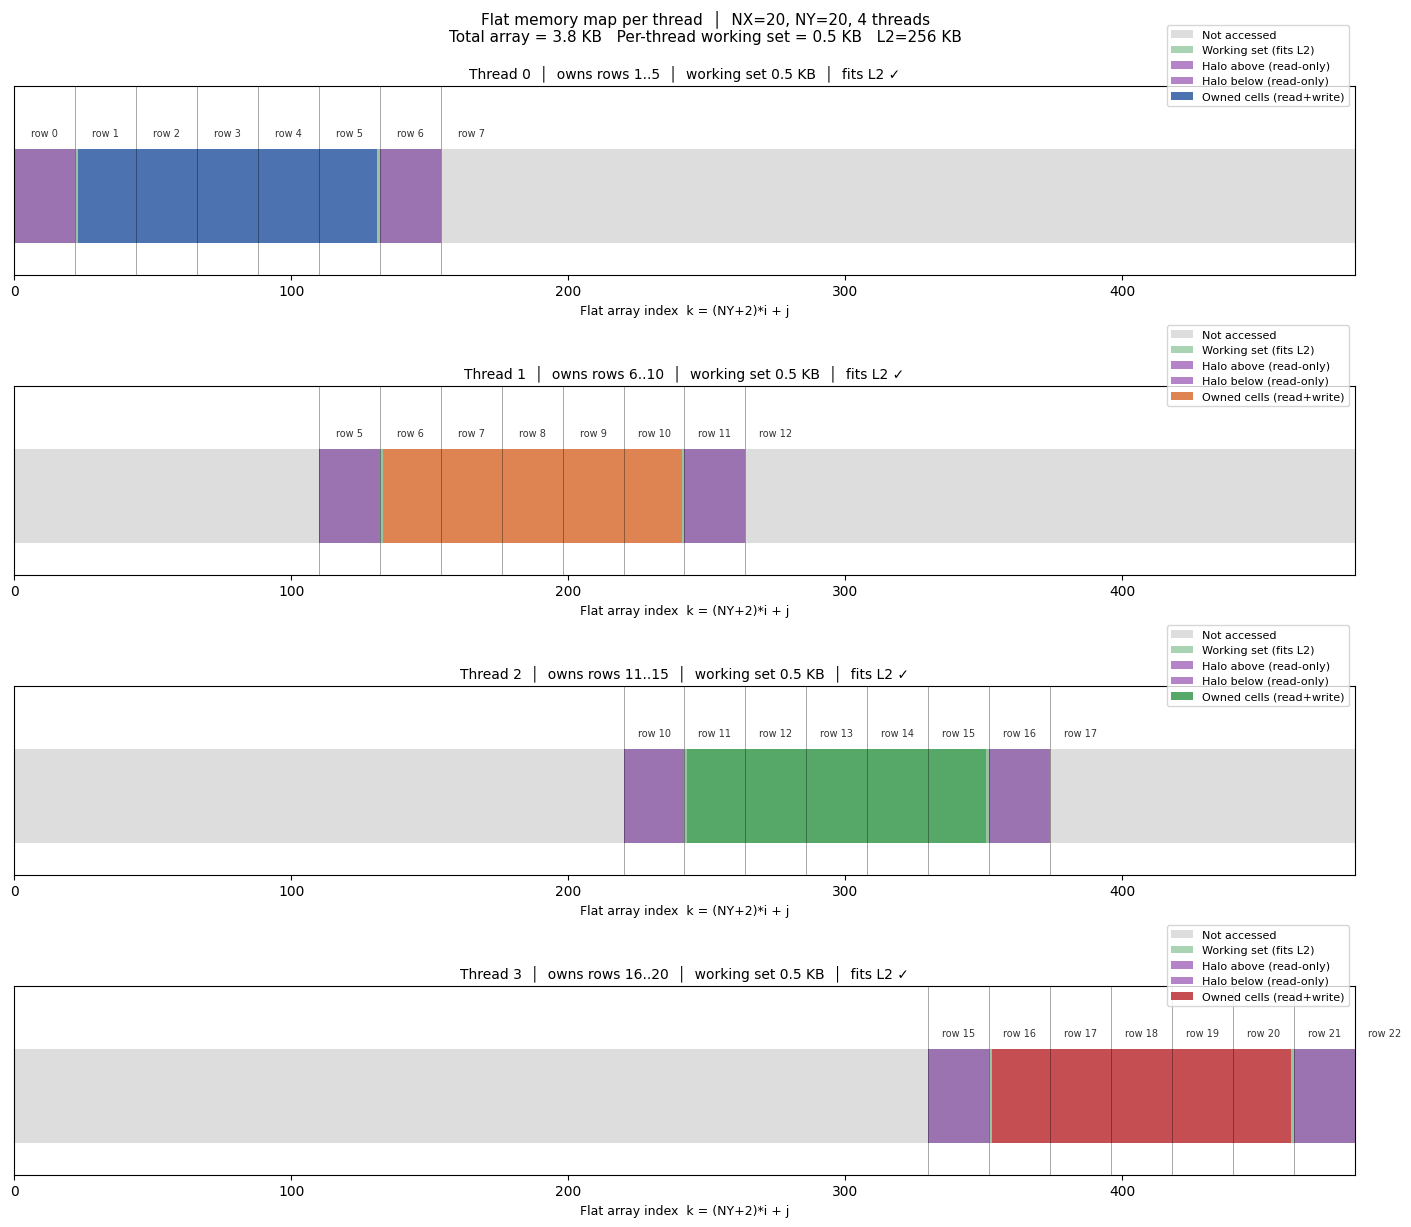

In [6]:
# %%
fig4, axes = plt.subplots(N_THREADS, 1, figsize=(14, 3 * N_THREADS),
                           constrained_layout=True)

ws_bytes = 3 * (NY + 2) * 8
fits_l2  = (ws_bytes <= L2_KB * 1024)

for t, ax in enumerate(axes):
    owned = [w for w in work_items if thread_of[w] == t]
    i_lo  = owned[0][0]
    i_hi  = owned[-1][0]

    # flat index ranges
    # owned interior cells
    own_start   = k(i_lo, 1)
    own_end     = k(i_hi, NY)
    # halo above (row i_lo - 1): needed but not owned
    halo_above_start = k(i_lo - 1, 0)
    halo_above_end   = k(i_lo - 1, NY + 1)
    # halo below (row i_hi + 1): needed but not owned
    halo_below_start = k(i_hi + 1, 0)
    halo_below_end   = k(i_hi + 1, NY + 1)
    # full working set in flat space
    ws_start = halo_above_start
    ws_end   = halo_below_end

    bar_y  = 0.5
    bar_h  = 0.6

    # entire array (grey)
    ax.barh(bar_y, N, left=0, height=bar_h,
            color='#DDDDDD', edgecolor='none', label='Not accessed')
    # working set
    ws_color = '#55A868' if fits_l2 else '#C44E52'
    ws_label = 'Working set (fits L2)' if fits_l2 else 'Working set (L2 MISS → DRAM)'
    ax.barh(bar_y, ws_end - ws_start + 1, left=ws_start, height=bar_h,
            color=ws_color, alpha=0.5, edgecolor='none', label=ws_label)
    # halo reads
    for hs, he, hlabel in [
            (halo_above_start, halo_above_end, 'Halo above (read-only)'),
            (halo_below_start, halo_below_end, 'Halo below (read-only)')]:
        ax.barh(bar_y, he - hs + 1, left=hs, height=bar_h,
                color='#9B59B6', alpha=0.75, edgecolor='none', label=hlabel)
    # owned cells
    ax.barh(bar_y, own_end - own_start + 1, left=own_start, height=bar_h,
            color=thread_colors[t], edgecolor='none', label='Owned cells (read+write)')

    # row boundary markers
    for row in range(i_lo - 1, i_hi + 3):
        ax.axvline(k(row, 0), color='black', linewidth=0.6, alpha=0.4)
        ax.text(k(row, 0) + (NY + 2) / 2, bar_y + bar_h / 2 + 0.07,
                f'row {row}', ha='center', va='bottom', fontsize=7, alpha=0.8)

    ax.set_xlim(0, N)
    ax.set_ylim(0, 1.2)
    ax.set_xlabel('Flat array index  k = (NY+2)*i + j', fontsize=9)
    ax.set_yticks([])
    ax.set_title(f'Thread {t}  │  owns rows {i_lo}..{i_hi}  │  '
                 f'working set {ws_bytes/1024:.1f} KB  │  '
                 f"{'fits L2 ✓' if fits_l2 else 'L2 miss ✗  → DRAM reads'}",
                 fontsize=10)

    # deduplicate legend labels
    handles, labels = ax.get_legend_handles_labels()
    seen = {}
    for h, l in zip(handles, labels):
        if l not in seen:
            seen[l] = h
    ax.legend(seen.values(), seen.keys(), loc='upper right', fontsize=8,
              bbox_to_anchor=(1.0, 1.35))

fig4.suptitle(
    f'Flat memory map per thread  │  NX={NX}, NY={NY}, {N_THREADS} threads\n'
    f'Total array = {N*8/1024:.1f} KB   Per-thread working set = {ws_bytes/1024:.1f} KB   '
    f'L2={L2_KB} KB',
    fontsize=11, y=1.01)

plt.savefig('plots/thread_memory_map.png', dpi=150, bbox_inches='tight')
plt.show()


### 5 — Animated cache-line sliding window

Saved: animations/cache_sliding_window.html


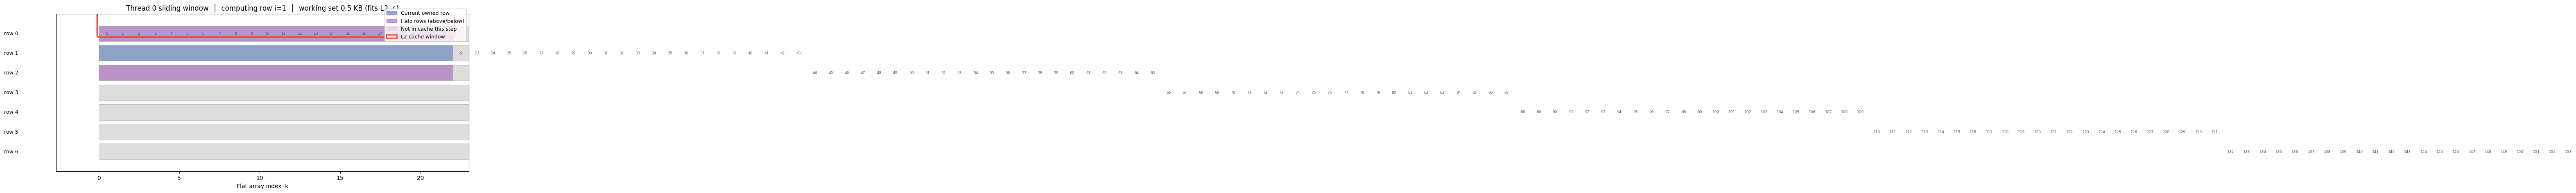

In [7]:

import os

# Pick thread 0's rows
owned_t0   = [w for w in work_items if thread_of[w] == 0]
rows_t0    = sorted(set(i for i,j in owned_t0))
i_lo_t0    = rows_t0[0]
i_hi_t0    = rows_t0[-1]

# All rows that will appear in the sliding window
window_rows = list(range(i_lo_t0 - 1, i_hi_t0 + 2))  # above_halo .. below_halo

fig5, ax5 = plt.subplots(figsize=(13, 5))

row_h     = 0.8
row_gap   = 1.0
n_display = len(window_rows)

bars      = []
row_texts = []
for idx, row in enumerate(window_rows):
    y   = (n_display - 1 - idx) * row_gap
    bar = ax5.barh(y, N, left=0, height=row_h,
                   color='#DDDDDD', edgecolor='#AAAAAA', linewidth=0.5)
    bars.append(bar)
    ax5.text(-5, y, f'row {row}', ha='right', va='center', fontsize=9)
    # mark individual cells
    for j in range(COLS):
        ki = COLS * row + j
        ax5.text(ki + 0.5, y, str(ki), ha='center', va='center',
                 fontsize=6.5, color='#555555')

# cache window rectangle
cache_rect = mpatches.FancyBboxPatch(
    (0, -0.5), COLS, 3 * row_gap,
    boxstyle='round,pad=0.1',
    linewidth=2.5, edgecolor='#E74C3C', facecolor='none',
    zorder=5, label='L2 cache window  (3 rows)')
ax5.add_patch(cache_rect)

active_bar_patches = []
slide_title = ax5.set_title('')

def update_slide(frame):
    # frame = index into rows_t0 (the owned rows)
    current_row = rows_t0[frame]
    above_row   = current_row - 1
    below_row   = current_row + 1

    for p in active_bar_patches:
        p.remove()
    active_bar_patches.clear()

    for idx, row in enumerate(window_rows):
        y = (n_display - 1 - idx) * row_gap
        if row == above_row:
            col = '#9B59B6'
            lbl = 'above (halo read)'
        elif row == current_row:
            col = thread_colors[0]
            lbl = 'current (owned)'
        elif row == below_row:
            col = '#9B59B6'
            lbl = 'below (halo read)'
        else:
            col = '#DDDDDD'
            lbl = None
        if col != '#DDDDDD':
            p = ax5.barh(y, COLS, left=0, height=row_h,
                         color=col, alpha=0.55, edgecolor='none', zorder=2)
            active_bar_patches.extend(p.patches)

    # move cache window — FancyBboxPatch uses set_bounds instead of set_xy
    above_y_idx = window_rows.index(above_row)
    above_y     = (n_display - 1 - above_y_idx) * row_gap
    cache_rect.set_bounds(0, above_y - row_h * 0.1, COLS, 3 * row_gap - row_gap * 0.2)

    ws_status = 'fits L2 ✓' if fits_l2 else 'L2 miss → DRAM ✗'
    slide_title.set_text(
        f'Thread 0 sliding window  │  computing row i={current_row}  │  '
        f'working set {ws_bytes/1024:.1f} KB ({ws_status})')

    return active_bar_patches + [cache_rect, slide_title]

ax5.set_xlim(-COLS * 0.12, COLS + 1)
ax5.set_ylim(-row_gap, n_display * row_gap)
ax5.set_xlabel('Flat array index  k', fontsize=10)
ax5.set_yticks([])

legend_els5 = [
    mpatches.Patch(color=thread_colors[0], alpha=0.6, label='Current owned row'),
    mpatches.Patch(color='#9B59B6',        alpha=0.6, label='Halo rows (above/below)'),
    mpatches.Patch(color='#DDDDDD',                   label='Not in cache this step'),
    mpatches.Patch(facecolor='none', edgecolor='#E74C3C', linewidth=2, label='L2 cache window'),
]
ax5.legend(handles=legend_els5, loc='upper right', bbox_to_anchor=(1.0, 1.05), fontsize=9)

anim5 = animation.FuncAnimation(
    fig5, update_slide,
    frames=len(rows_t0), interval=600, blit=False, repeat=True)

plt.tight_layout()

os.makedirs('animations', exist_ok=True)
html5 = anim5.to_jshtml()
with open('animations/cache_sliding_window.html', 'w') as f:
    f.write(html5)
print("Saved: animations/cache_sliding_window.html")
display(HTML(html5))


### 6 — Summary: how to know if you will have cache misses

```
Working set of 1 thread for 1 row of the stencil:
 
    3 rows × (NY+2) doubles × 8 bytes/double
 
    NY=20   →    3×22×8 =   528 B   << L1 (32 KB)   → all hits
    NY=1300 →  3×1302×8 ≈  30 KB   ≈  L1            → borderline
    NY=10000→  3×10002×8≈ 234 KB   ≈  L2            → L2 boundary
    NY=80000→  3×80002×8≈ 1875 KB  >> L2            → DRAM reads
 ```
 
# **How to measure at runtime on Leonardo:**
 ```bash
    PAPI hardware counters (if available)
    perf stat -e L1-dcache-load-misses,L2-dcache-load-misses ./jacobi_just_omp 200 200

## or with likwid
    likwid-perfctr -C 0-3 -g MEM_DP ./jacobi_just_omp 200 200
```
 
### **Key takeaway:** for the grids in `main.py` (NX=NY up to 400),
### the working set per thread is `3×402×8 = 9.6 KB` — comfortably inside L1.
### Cache misses are NOT the bottleneck for these sizes; thread-spawn overhead
### and the OMP reduction tree are the limiting factors.
